# NeuroSense — Frozen DistilBERT Genuine-CHAT Experiment

This notebook runs **only** on 362 header-confirmed training and 92 header-confirmed validation Pitt Cookie Theft CHAT transcripts. It excludes 062-3, 190-1, and 190-2, and has no frozen-test input or evaluation path.

Run this notebook in Google Colab. Do not run it locally: downloading the DistilBERT model and extracting embeddings are deliberately Colab-only operations.

## 1. Mount Drive and define the fixed experiment paths

In [2]:
from google.colab import drive
from pathlib import Path
import os, sys

drive.mount('/content/drive')
PROJECT_DIR = Path('/content/drive/MyDrive/NeuroSense_NLP_Colab')
if not PROJECT_DIR.is_dir():
    raise FileNotFoundError(f'Upload the prepared project files first: {PROJECT_DIR}')
os.chdir(PROJECT_DIR)
sys.path.insert(0, str(PROJECT_DIR))

TRAIN_MANIFEST = PROJECT_DIR / 'speech_model/data/transcript_manifests/train_chat_confirmed.csv'
VALID_MANIFEST = PROJECT_DIR / 'speech_model/data/transcript_manifests/valid_chat_confirmed.csv'
PITT_ROOT = PROJECT_DIR / 'Pitt'
RUN_DIR = PROJECT_DIR / 'distilbert_frozen_genuine_chat_v1'
EMBED_CACHE_DIR = RUN_DIR / 'embedding_cache'
MATRIX_DIR = RUN_DIR / 'embedding_matrices'

# The notebook intentionally has no test-manifest path.
print('Project:', PROJECT_DIR)
print('Run artifacts will be checkpointed in:', RUN_DIR)

Mounted at /content/drive
Project: /content/drive/MyDrive/NeuroSense_NLP_Colab
Run artifacts will be checkpointed in: /content/drive/MyDrive/NeuroSense_NLP_Colab/distilbert_frozen_genuine_chat_v1


## 2. Install Colab dependencies and verify the frozen encoder

In [3]:
# Run in Colab only. This can download dependencies/model files to the Colab/Drive environment, never locally.
!pip install -q -r requirements_nlp.txt

import torch, transformers, sklearn, pandas as pd, numpy as np
print('torch:', torch.__version__)
print('transformers:', transformers.__version__)
print('scikit-learn:', sklearn.__version__)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Frozen embedding device:', DEVICE)
assert DEVICE in {'cpu', 'cuda'}

torch: 2.11.0+cu130
transformers: 5.17.0
scikit-learn: 1.6.1
Frozen embedding device: cuda


## 3. Fail-closed genuine-CHAT preflight

In [4]:
from speech_model.nlp.chat import PittCookieResolver, recording_key

PENDING_KEYS = {'062-3', '190-1', '190-2'}
REQUIRED_COLUMNS = {'audio_path', 'label', 'participant_id', 'sha256', 'raw_transcript', 'cleaned_transcript',
                    'chat_source_path', 'chat_media_id', 'chat_task', 'chat_task_confirmed'}

def load_and_verify_confirmed(path, expected_count, split_name):
    if not path.is_file():
        raise FileNotFoundError(f'{split_name}: missing verified manifest: {path}')
    frame = pd.read_csv(path, dtype={'participant_id': str})
    missing = REQUIRED_COLUMNS - set(frame.columns)
    if len(frame) != expected_count or missing:
        raise RuntimeError(f'{split_name}: expected {expected_count} verified rows; got {len(frame)}; missing={sorted(missing)}')
    if not set(frame['label']).issubset({'control', 'dementia'}):
        raise RuntimeError(f'{split_name}: invalid diagnosis label')
    if not frame['chat_task_confirmed'].astype(str).str.lower().eq('true').all() or not frame['chat_task'].astype(str).str.lower().eq('cookie').all():
        raise RuntimeError(f'{split_name}: non-confirmed/non-Cookie transcript found')
    if frame[['raw_transcript', 'cleaned_transcript']].isna().any().any() or not frame['raw_transcript'].str.strip().ne('').all() or not frame['cleaned_transcript'].str.strip().ne('').all():
        raise RuntimeError(f'{split_name}: missing or empty participant transcript')
    if frame['raw_transcript'].str.contains('placeholder|transcript pending', case=False, regex=True).any():
        raise RuntimeError(f'{split_name}: placeholder transcript rejected')
    if any(recording_key(p) in PENDING_KEYS for p in frame['audio_path']):
        raise RuntimeError(f'{split_name}: provenance-pending recording included')
    if frame['sha256'].duplicated().any() or frame['audio_path'].duplicated().any():
        raise RuntimeError(f'{split_name}: duplicate recording/hash')
    if (frame.groupby('participant_id')['label'].nunique() != 1).any():
        raise RuntimeError(f'{split_name}: conflicting participant label')
    return frame

# if not (PITT_ROOT / 'Control/cookie').is_dir() or not (PITT_ROOT / 'Dementia/cookie').is_dir():
#     raise FileNotFoundError('Upload Pitt/Control/cookie and Pitt/Dementia/cookie before proceeding')

control_files = list((PITT_ROOT / "Control/cookie").glob("*.cha"))
dementia_files = list((PITT_ROOT / "Dementia/cookie").glob("*.cha"))

print(f"Control CHAT files: {len(control_files)}")
print(f"Dementia CHAT files: {len(dementia_files)}")

if len(control_files) < 243 or len(dementia_files) < 309:
    raise RuntimeError(
        "Cookie CHAT inventory is smaller than the verified source inventory"
    )

# print("Additional CHAT files retained; verifying each confirmed transcript.")
# if len(list((PITT_ROOT / 'Control/cookie').glob('*.cha'))) != 243 or len(list((PITT_ROOT / 'Dementia/cookie').glob('*.cha'))) != 309:
#     raise RuntimeError('Unexpected Cookie CHAT inventory; expected 243 Control + 309 Dementia files')

train_df = load_and_verify_confirmed(TRAIN_MANIFEST, 362, 'train')
valid_df = load_and_verify_confirmed(VALID_MANIFEST, 92, 'validation')
if set(train_df.participant_id) & set(valid_df.participant_id):
    raise RuntimeError('Participant overlap between train and validation')
if set(train_df.sha256) & set(valid_df.sha256):
    raise RuntimeError('SHA256 overlap between train and validation')

# Re-parse every source CHAT file in Colab. This ignores Windows source paths and refuses fallback text.
resolver = PittCookieResolver(PITT_ROOT)
for split_name, frame in [('train', train_df), ('validation', valid_df)]:
    for row in frame.itertuples(index=False):
        parsed = resolver.resolve(row.audio_path, row.label, require_confirmed_task=True)
        if parsed.media_id != row.chat_media_id or parsed.participant_raw != row.raw_transcript or parsed.participant_clean != row.cleaned_transcript:
            raise RuntimeError(f'{split_name}: CHAT parser/provenance mismatch for {row.audio_path}')

print(f'PASS: {len(train_df)} train + {len(valid_df)} validation = {len(train_df) + len(valid_df)} genuine transcripts')
print(f'PASS: participants train={train_df.participant_id.nunique()}, validation={valid_df.participant_id.nunique()}, overlap=0')
print('PASS: no frozen test manifest loaded; no pending transcript admitted')

Control CHAT files: 253
Dementia CHAT files: 310
PASS: 362 train + 92 validation = 454 genuine transcripts
PASS: participants train=201, validation=51, overlap=0
PASS: no frozen test manifest loaded; no pending transcript admitted


## 4. Extract linguistic and TextBlob features from genuine participant speech

In [5]:
from speech_model.nlp.features import HAS_TEXTBLOB, extract_all_linguistic_features
if not HAS_TEXTBLOB:
    raise RuntimeError('TextBlob is required for this planned comparison')

def feature_frame(frame):
    values = pd.DataFrame([extract_all_linguistic_features(text) for text in frame['raw_transcript']])
    if values.isna().any().any():
        raise RuntimeError('Missing handcrafted feature value')
    return values

train_features = feature_frame(train_df)
valid_features = feature_frame(valid_df)
if list(train_features.columns) != list(valid_features.columns):
    raise RuntimeError('Feature schema mismatch')
SENTIMENT_COLUMNS = ['polarity', 'subjectivity']
LINGUISTIC_COLUMNS = [c for c in train_features.columns if c not in SENTIMENT_COLUMNS]
X_train_ling = train_features[LINGUISTIC_COLUMNS].to_numpy(dtype=np.float32)
X_valid_ling = valid_features[LINGUISTIC_COLUMNS].to_numpy(dtype=np.float32)
X_train_sent = train_features[SENTIMENT_COLUMNS].to_numpy(dtype=np.float32)
X_valid_sent = valid_features[SENTIMENT_COLUMNS].to_numpy(dtype=np.float32)
print('Linguistic shape:', X_train_ling.shape, X_valid_ling.shape, '| TextBlob shape:', X_train_sent.shape, X_valid_sent.shape)

Linguistic shape: (362, 23) (92, 23) | TextBlob shape: (362, 2) (92, 2)


## 5. Frozen DistilBERT embeddings with resumable Google Drive cache

In [5]:
from speech_model.nlp.embeddings import extract_single_embedding, get_text_hash
import json

MODEL_NAME = 'distilbert-base-uncased'

def atomic_json(path, payload):
    temp = path.with_suffix(path.suffix + '.tmp')
    temp.write_text(json.dumps(payload, indent=2), encoding='utf-8')
    temp.replace(path)

def embed_split(frame, split_name):
    split_cache = EMBED_CACHE_DIR / split_name
    matrix_path = MATRIX_DIR / f'{split_name}_distilbert_embeddings.npy'
    progress_path = MATRIX_DIR / f'{split_name}_embedding_progress.json'
    split_cache.mkdir(parents=True, exist_ok=True); MATRIX_DIR.mkdir(parents=True, exist_ok=True)
    texts = frame['cleaned_transcript'].tolist()
    if any(not isinstance(text, str) or not text.strip() for text in texts):
        raise RuntimeError(f'{split_name}: empty text is prohibited')
    expected_hashes = [get_text_hash(text) for text in texts]
    if matrix_path.is_file():
        matrix = np.load(matrix_path)
        if matrix.shape == (len(texts), 768):
            print(f'{split_name}: loaded completed matrix from Drive cache')
            return matrix
    embeddings = []
    for index, text in enumerate(texts, start=1):
        embedding = extract_single_embedding(text, cache_dir=split_cache, device=DEVICE, model_name=MODEL_NAME)
        if embedding.shape != (768,):
            raise RuntimeError(f'{split_name}: unexpected embedding shape at row {index}')
        embeddings.append(embedding)
        atomic_json(progress_path, {'split': split_name, 'completed_rows': index, 'total_rows': len(texts),
                                    'last_text_sha256': expected_hashes[index - 1], 'model': MODEL_NAME})
    matrix = np.asarray(embeddings, dtype=np.float32)
    np.save(matrix_path, matrix)
    atomic_json(progress_path, {'split': split_name, 'completed_rows': len(texts), 'total_rows': len(texts),
                                'status': 'complete', 'model': MODEL_NAME, 'text_sha256': expected_hashes})
    return matrix

# Per-recording .npy cache files are committed to Drive after every successful embedding. Re-running resumes them.
X_train_emb = embed_split(train_df, 'train')
X_valid_emb = embed_split(valid_df, 'validation')
print('Frozen DistilBERT shapes:', X_train_emb.shape, X_valid_emb.shape)

train: loaded completed matrix from Drive cache
validation: loaded completed matrix from Drive cache
Frozen DistilBERT shapes: (362, 768) (92, 768)


## 6. Training-only logistic-regression comparisons and participant-level validation

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from speech_model.nlp.evaluation import evaluate_participant_level
import joblib

y_train = train_df['label'].map({'control': 0, 'dementia': 1}).to_numpy()
CONFIGS = {
    'distilbert_only': (X_train_emb, X_valid_emb, ['distilbert_mean_pool_0...767']),
    'distilbert_plus_linguistic': (np.hstack([X_train_emb, X_train_ling]), np.hstack([X_valid_emb, X_valid_ling]), ['distilbert_mean_pool_0...767'] + LINGUISTIC_COLUMNS),
    'distilbert_plus_linguistic_textblob': (np.hstack([X_train_emb, X_train_ling, X_train_sent]), np.hstack([X_valid_emb, X_valid_ling, X_valid_sent]), ['distilbert_mean_pool_0...767'] + LINGUISTIC_COLUMNS + SENTIMENT_COLUMNS),
}

RUN_DIR.mkdir(parents=True, exist_ok=True)
metrics_by_config, participant_tables = {}, []
recording_predictions = valid_df[['audio_path', 'participant_id', 'label', 'sha256', 'chat_source_path', 'chat_media_id']].copy()
for name, (x_train, x_valid, feature_names) in CONFIGS.items():
    scaler = StandardScaler().fit(x_train)  # fit only on train
    model = LogisticRegression(class_weight='balanced', random_state=42, solver='liblinear', max_iter=1000)
    model.fit(scaler.transform(x_train), y_train)
    probabilities = model.predict_proba(scaler.transform(x_valid))[:, 1]
    metrics, participant_table = evaluate_participant_level(valid_df, probabilities, threshold=0.5, aggregation_method='mean')
    metrics_by_config[name] = metrics
    recording_predictions[f'probability_{name}'] = probabilities
    recording_predictions[f'prediction_{name}'] = (probabilities >= 0.5).astype(int)
    participant_tables.append(participant_table.rename(columns={'predicted_prob': f'probability_{name}', 'predicted_label': f'prediction_{name}', 'correct': f'correct_{name}'}))
    joblib.dump({'model': model, 'scaler': scaler, 'feature_names': feature_names, 'label_map': {'control': 0, 'dementia': 1},
                 'train_rows': len(train_df), 'source': 'verified Pitt CHAT *PAR only', 'model': MODEL_NAME}, RUN_DIR / f'{name}_model.joblib')

participant_predictions = participant_tables[0]
for table in participant_tables[1:]:
    participant_predictions = participant_predictions.merge(table, on=['participant_id', 'numeric_label'], how='inner')
print(pd.DataFrame(metrics_by_config).T[['balanced_accuracy', 'sensitivity', 'specificity', 'precision', 'f1_score', 'roc_auc', 'pr_auc']])

                                    balanced_accuracy sensitivity specificity  \
distilbert_only                              0.838384    0.787879    0.888889   
distilbert_plus_linguistic                   0.838384    0.787879    0.888889   
distilbert_plus_linguistic_textblob          0.838384    0.787879    0.888889   

                                    precision  f1_score   roc_auc    pr_auc  
distilbert_only                      0.928571  0.852459  0.867003  0.940814  
distilbert_plus_linguistic           0.928571  0.852459  0.858586  0.937568  
distilbert_plus_linguistic_textblob  0.928571  0.852459  0.861953  0.938234  


## 7. Save Drive artifacts and validation report

In [7]:
recording_predictions.to_csv(RUN_DIR / 'validation_recording_predictions.csv', index=False)
participant_predictions.to_csv(RUN_DIR / 'validation_participant_predictions.csv', index=False)
(RUN_DIR / 'feature_definitions.json').write_text(json.dumps({'linguistic': LINGUISTIC_COLUMNS, 'textblob': SENTIMENT_COLUMNS, 'model': MODEL_NAME}, indent=2), encoding='utf-8')
(RUN_DIR / 'validation_metrics.json').write_text(json.dumps(metrics_by_config, indent=2), encoding='utf-8')

def cm_line(metrics):
    cm = metrics['confusion_matrix']; return f"TN={cm['tn']}, FP={cm['fp']}, FN={cm['fn']}, TP={cm['tp']}"
report = ['# Frozen DistilBERT Genuine-CHAT Validation Report', '',
          'Frozen test was not loaded or evaluated. The three task-provenance-pending recordings were excluded.',
          f'Train: {len(train_df)} recordings / {train_df.participant_id.nunique()} participants.',
          f'Validation: {len(valid_df)} recordings / {valid_df.participant_id.nunique()} participants.',
          'Preflight passed: parser provenance, non-empty text, zero participant overlap, and zero SHA256 overlap.', '',
          '| Configuration | Balanced accuracy | Dementia recall | Control recall | Precision | F1 | ROC-AUC | PR-AUC | Confusion matrix |',
          '|---|---:|---:|---:|---:|---:|---:|---:|---|']
for name, metrics in metrics_by_config.items():
    report.append(f"| {name} | {metrics['balanced_accuracy']:.4f} | {metrics['sensitivity']:.4f} | {metrics['specificity']:.4f} | {metrics['precision']:.4f} | {metrics['f1_score']:.4f} | {metrics['roc_auc']:.4f} | {metrics['pr_auc']:.4f} | {cm_line(metrics)} |")
report.append('AUC metrics use continuous mean participant probabilities; thresholded metrics use 0.5. Models/scalers were fit using training data only.')
(RUN_DIR / 'FROZEN_DISTILBERT_VALIDATION_REPORT.md').write_text('\n'.join(report) + '\n', encoding='utf-8')
print('Saved checkpointed embeddings, models, predictions, metrics, and report to:', RUN_DIR)

Saved checkpointed embeddings, models, predictions, metrics, and report to: /content/drive/MyDrive/NeuroSense_NLP_Colab/distilbert_frozen_genuine_chat_v1


In [10]:
from pathlib import Path
import pandas as pd

# Find the actual frozen test manifest in your mounted Google Drive
matches = list(
    Path("/content/drive/MyDrive").rglob("frozen_test.csv")
)

print("Found:")
for p in matches:
    print(" -", p)

assert len(matches) >= 1, "frozen_test.csv was not found in Google Drive."

TEST_MANIFEST = matches[0]

test_df = pd.read_csv(TEST_MANIFEST)

print("\nUsing:", TEST_MANIFEST)
print("Shape:", test_df.shape)
print("\nColumns:", test_df.columns.tolist())
print("\nFirst rows:")
display(test_df.head())

Found:
 - /content/drive/MyDrive/NEUROSENSE(SPEECH AND STMT ANALYSIS)/NeuroSense_Backups/v2_completed_20260927_111714/frozen_test.csv

Using: /content/drive/MyDrive/NEUROSENSE(SPEECH AND STMT ANALYSIS)/NeuroSense_Backups/v2_completed_20260927_111714/frozen_test.csv
Shape: (69, 13)

Columns: ['audio_path', 'label', 'participant_id', 'session', 'is_copy', 'duration_s', 'sample_rate', 'channels', 'file_bytes', 'sha256', 'readable', 'error', 'source']

First rows:


,audio_path,label,participant_id,session,is_copy,duration_s,sample_rate,channels,file_bytes,sha256,readable,error,source
0,c:\Users\Dharmaraj\Downloads\speech proceesing...,dementia,16,0,False,60.184,44100,1,5308240,8d5b343f2b6f5c175b88e456beda85a49cc7fb6e597a60...,True,NaN,dementia
1,c:\Users\Dharmaraj\Downloads\speech proceesing...,dementia,16,1,False,45.686,44100,1,4029512,dfaf18060dada6a0316b0b22e331c6c3b6a5c986179eb9...,True,NaN,dementia
2,c:\Users\Dharmaraj\Downloads\speech proceesing...,dementia,16,3,False,34.790,44100,1,3068510,9c67c6556fc7fcfb573a3a276e1fe01e9192d26a8b1572...,True,NaN,dementia
3,c:\Users\Dharmaraj\Downloads\speech proceesing...,dementia,16,4,False,80.011,44100,1,7057010,3d77c433215747d434a92957094dd2c21c895b25357ddb...,True,NaN,dementia
4,c:\Users\Dharmaraj\Downloads\speech proceesing...,dementia,585,0,False,80.031,44100,1,7058816,f236f15eddd4ac1e89ba58765314ad2e20f8d2b3b817be...,True,NaN,dementia


In [11]:
# ============================================================
# FINAL NLP FROZEN TEST EVALUATION
# Existing DistilBERT-only pipeline
# NO test tuning / NO threshold tuning / NO new architecture
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd
import joblib

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
)

# ------------------------------------------------------------
# 1. Load the actual frozen 69-recording manifest
# ------------------------------------------------------------

TEST_MANIFEST = Path(
    "/content/drive/MyDrive/NEUROSENSE(SPEECH AND STMT ANALYSIS)/"
    "NeuroSense_Backups/v2_completed_20260927_111714/frozen_test.csv"
)

assert TEST_MANIFEST.is_file(), f"Missing: {TEST_MANIFEST}"

test_df = pd.read_csv(
    TEST_MANIFEST,
    dtype={"participant_id": str}
)

print("Frozen test manifest:", TEST_MANIFEST)
print("Rows:", len(test_df))

assert len(test_df) == 69, f"Expected 69 recordings, got {len(test_df)}"

# ------------------------------------------------------------
# 2. Verify labels and frozen split
# ------------------------------------------------------------

assert set(test_df["label"]) == {"control", "dementia"}

test_df["numeric_label"] = test_df["label"].map({
    "control": 0,
    "dementia": 1
}).astype(int)

print("\nClass distribution:")
print(test_df["label"].value_counts())

assert (test_df["label"] == "control").sum() == 20
assert (test_df["label"] == "dementia").sum() == 49

# Participant-level leakage check
test_participants = set(test_df["participant_id"])

assert not (
    test_participants &
    set(train_df["participant_id"].astype(str))
), "TEST/TRAIN participant overlap detected!"

assert not (
    test_participants &
    set(valid_df["participant_id"].astype(str))
), "TEST/VALID participant overlap detected!"

print(
    "\nParticipant leakage check: PASS"
    f"\nTest participants: {len(test_participants)}"
)

# ------------------------------------------------------------
# 3. Resolve genuine Pitt Cookie transcripts
# ------------------------------------------------------------

from speech_model.nlp.chat import recording_key

resolved = []

for row in test_df.itertuples(index=False):

    parsed = resolver.resolve(
        row.audio_path,
        row.label,
        require_confirmed_task=True
    )

    resolved.append({
        "audio_path": row.audio_path,
        "label": row.label,
        "participant_id": str(row.participant_id),
        "numeric_label": int(row.numeric_label),
        "sha256": row.sha256,
        "chat_source_path": parsed.source_path,
        "chat_media_id": parsed.media_id,
        "raw_transcript": parsed.participant_raw,
        "cleaned_transcript": parsed.participant_clean,
    })

test_chat_df = pd.DataFrame(resolved)

assert len(test_chat_df) == 69
assert test_chat_df["cleaned_transcript"].notna().all()
assert test_chat_df["cleaned_transcript"].str.strip().ne("").all()

# Reject placeholder text
assert not test_chat_df["raw_transcript"].str.contains(
    "placeholder|transcript pending",
    case=False,
    regex=True
).any()

# Reject provenance-pending recordings
PENDING_KEYS = {"062-3", "190-1", "190-2"}

assert not any(
    recording_key(p) in PENDING_KEYS
    for p in test_chat_df["audio_path"]
)

# No duplicate recordings/hashes
assert not test_chat_df["audio_path"].duplicated().any()
assert not test_chat_df["sha256"].duplicated().any()

print("\nCHAT transcript resolution: PASS")
print("Confirmed Cookie transcripts:", len(test_chat_df))

# Save verified frozen-test transcript manifest
TEST_RUN_DIR = RUN_DIR / "frozen_test_distilbert_only"
TEST_RUN_DIR.mkdir(parents=True, exist_ok=True)

test_chat_df.to_csv(
    TEST_RUN_DIR / "frozen_test_chat_manifest.csv",
    index=False
)

# ------------------------------------------------------------
# 4. Generate frozen-test DistilBERT embeddings
# ------------------------------------------------------------

X_test_emb = embed_split(
    test_chat_df,
    "frozen_test"
)

assert X_test_emb.shape == (69, 768)

print("\nFrozen-test embeddings:", X_test_emb.shape)

# ------------------------------------------------------------
# 5. Recreate the SAME DistilBERT-only classifier
#    using ONLY the original training set
# ------------------------------------------------------------

y_train = train_df["label"].map({
    "control": 0,
    "dementia": 1
}).to_numpy()

scaler_test = StandardScaler().fit(X_train_emb)

model_test = LogisticRegression(
    class_weight="balanced",
    random_state=42,
    solver="liblinear",
    max_iter=1000
)

model_test.fit(
    scaler_test.transform(X_train_emb),
    y_train
)

# Save corrected artifact
joblib.dump(
    {
        "model": model_test,
        "scaler": scaler_test,
        "feature_names": [
            "distilbert_mean_pool_0...767"
        ],
        "label_map": {
            "control": 0,
            "dementia": 1
        },
        "train_rows": len(train_df),
        "source": "verified Pitt CHAT *PAR only",
        "model_name": MODEL_NAME,
    },
    RUN_DIR / "distilbert_only_model.joblib"
)

print("\nCorrected model artifact saved.")

# ------------------------------------------------------------
# 6. FINAL 69-RECORDING PREDICTIONS
# ------------------------------------------------------------

y_test = test_chat_df["numeric_label"].to_numpy()

test_prob = model_test.predict_proba(
    scaler_test.transform(X_test_emb)
)[:, 1]

# IMPORTANT:
# Keep the same 0.50 threshold already used during validation.
test_pred = (test_prob >= 0.50).astype(int)

# ------------------------------------------------------------
# 7. RECORDING-LEVEL METRICS
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test,
    test_pred,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

recording_metrics = {
    "n_recordings": int(len(y_test)),
    "accuracy": float(
        accuracy_score(y_test, test_pred)
    ),
    "balanced_accuracy": float(
        balanced_accuracy_score(y_test, test_pred)
    ),
    "dementia_recall": float(
        recall_score(y_test, test_pred, pos_label=1)
    ),
    "control_recall": float(
        recall_score(y_test, test_pred, pos_label=0)
    ),
    "precision": float(
        precision_score(y_test, test_pred, zero_division=0)
    ),
    "f1": float(
        f1_score(y_test, test_pred, zero_division=0)
    ),
    "roc_auc": float(
        roc_auc_score(y_test, test_prob)
    ),
    "pr_auc": float(
        average_precision_score(y_test, test_prob)
    ),
    "confusion_matrix": cm.tolist(),
}

# ------------------------------------------------------------
# 8. Participant-level aggregation
# ------------------------------------------------------------

recording_predictions = test_chat_df[
    [
        "audio_path",
        "participant_id",
        "label",
        "numeric_label",
        "sha256",
        "chat_source_path",
        "chat_media_id",
    ]
].copy()

recording_predictions["dementia_probability"] = test_prob
recording_predictions["prediction"] = test_pred

participant_predictions = (
    recording_predictions
    .groupby("participant_id", as_index=False)
    .agg(
        numeric_label=("numeric_label", "first"),
        dementia_probability=("dementia_probability", "mean"),
        n_recordings=("audio_path", "count")
    )
)

participant_predictions["prediction"] = (
    participant_predictions["dementia_probability"] >= 0.50
).astype(int)

yp = participant_predictions["numeric_label"].to_numpy()
pp = participant_predictions["dementia_probability"].to_numpy()
p_pred = participant_predictions["prediction"].to_numpy()

participant_cm = confusion_matrix(
    yp,
    p_pred,
    labels=[0, 1]
)

participant_metrics = {
    "n_participants": int(len(participant_predictions)),
    "accuracy": float(
        accuracy_score(yp, p_pred)
    ),
    "balanced_accuracy": float(
        balanced_accuracy_score(yp, p_pred)
    ),
    "dementia_recall": float(
        recall_score(yp, p_pred, pos_label=1)
    ),
    "control_recall": float(
        recall_score(yp, p_pred, pos_label=0)
    ),
    "precision": float(
        precision_score(yp, p_pred, zero_division=0)
    ),
    "f1": float(
        f1_score(yp, p_pred, zero_division=0)
    ),
    "roc_auc": float(
        roc_auc_score(yp, pp)
    ),
    "pr_auc": float(
        average_precision_score(yp, pp)
    ),
    "confusion_matrix": participant_cm.tolist(),
}

# ------------------------------------------------------------
# 9. Save final artifacts
# ------------------------------------------------------------

recording_predictions.to_csv(
    TEST_RUN_DIR / "frozen_test_recording_predictions.csv",
    index=False
)

participant_predictions.to_csv(
    TEST_RUN_DIR / "frozen_test_participant_predictions.csv",
    index=False
)

results = {
    "recording_level": recording_metrics,
    "participant_level": participant_metrics,
    "protocol": {
        "model": "DistilBERT embeddings + Logistic Regression",
        "embedding_model": MODEL_NAME,
        "threshold": 0.50,
        "n_test_recordings": 69,
        "test_controls": 20,
        "test_dementia": 49,
        "retraining_on_test": False,
        "threshold_tuning_on_test": False,
    }
}

(TEST_RUN_DIR / "frozen_test_metrics.json").write_text(
    json.dumps(results, indent=2),
    encoding="utf-8"
)

# ------------------------------------------------------------
# 10. FINAL OUTPUT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL NLP FROZEN TEST — RECORDING LEVEL")
print("=" * 70)

for key, value in recording_metrics.items():
    if key == "confusion_matrix":
        continue

    if isinstance(value, float):
        print(f"{key:25s}: {value:.4f}")
    else:
        print(f"{key:25s}: {value}")

print("\nConfusion matrix [Control, Dementia]:")
print(cm)

print("\n" + "=" * 70)
print("FINAL NLP FROZEN TEST — PARTICIPANT LEVEL")
print("=" * 70)

for key, value in participant_metrics.items():
    if key == "confusion_matrix":
        continue

    if isinstance(value, float):
        print(f"{key:25s}: {value:.4f}")
    else:
        print(f"{key:25s}: {value}")

print("\nParticipant confusion matrix [Control, Dementia]:")
print(participant_cm)

print("\nArtifacts saved to:")
print(TEST_RUN_DIR)

print("\n" + "=" * 70)
print("FROZEN NLP TEST COMPLETE")
print("=" * 70)

Frozen test manifest: /content/drive/MyDrive/NEUROSENSE(SPEECH AND STMT ANALYSIS)/NeuroSense_Backups/v2_completed_20260927_111714/frozen_test.csv
Rows: 69

Class distribution:
label
dementia    49
control     20
Name: count, dtype: int64

Participant leakage check: PASS
Test participants: 37

CHAT transcript resolution: PASS
Confirmed Cookie transcripts: 69


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Frozen-test embeddings: (69, 768)

Corrected model artifact saved.

FINAL NLP FROZEN TEST — RECORDING LEVEL
n_recordings             : 69
accuracy                 : 0.6522
balanced_accuracy        : 0.7255
dementia_recall          : 0.5510
control_recall           : 0.9000
precision                : 0.9310
f1                       : 0.6923
roc_auc                  : 0.7847
pr_auc                   : 0.9101

Confusion matrix [Control, Dementia]:
[[18  2]
 [22 27]]

FINAL NLP FROZEN TEST — PARTICIPANT LEVEL
n_participants           : 37
accuracy                 : 0.7838
balanced_accuracy        : 0.8621
dementia_recall          : 0.7241
control_recall           : 1.0000
precision                : 1.0000
f1                       : 0.8400
roc_auc                  : 0.8793
pr_auc                   : 0.9688

Participant confusion matrix [Control, Dementia]:
[[ 8  0]
 [ 8 21]]

Artifacts saved to:
/content/drive/MyDrive/NeuroSense_NLP_Colab/distilbert_frozen_genuine_chat_v1/frozen_test_disti

In [8]:
# ============================================================
# FINAL FROZEN TEST — DISTILBERT ONLY
# DO NOT TUNE / RETRAIN / CHANGE THRESHOLD
# ============================================================

from pathlib import Path
import zipfile
import shutil
import json
import numpy as np
import pandas as pd
import joblib

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
)

from speech_model.nlp.chat import PittCookieResolver, recording_key

# ------------------------------------------------------------
# 1. Locate the canonical frozen 69-recording test manifest
# ------------------------------------------------------------

CANDIDATES = [
    PROJECT_DIR / "speech_model/data/manifests/test.csv",
    Path("/content/NeuroSense_Colab/speech_model/data/manifests/test.csv"),
]

test_manifest = next((p for p in CANDIDATES if p.is_file()), None)

# If the acoustic project was not extracted in this runtime,
# extract ONLY its manifest from the project ZIP.
if test_manifest is None:
    project_zip = Path(
        "/content/drive/MyDrive/NeuroSense/NeuroSense_Colab_Project.zip"
    )

    if not project_zip.is_file():
        raise FileNotFoundError(
            "Frozen test manifest not found and "
            "NeuroSense_Colab_Project.zip is unavailable."
        )

    extract_root = Path("/content/NeuroSense_FrozenTest")
    extract_root.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(project_zip, "r") as z:
        matches = [
            n for n in z.namelist()
            if n.endswith("speech_model/data/manifests/test.csv")
        ]

        if not matches:
            raise FileNotFoundError(
                "Could not find speech_model/data/manifests/test.csv "
                "inside NeuroSense_Colab_Project.zip"
            )

        member = matches[0]
        z.extract(member, extract_root)

    test_manifest = extract_root / member

print("Frozen test manifest:", test_manifest)

# ------------------------------------------------------------
# 2. Load and verify the frozen test set
# ------------------------------------------------------------

test_df = pd.read_csv(
    test_manifest,
    dtype={"participant_id": str}
)

print("\nTest rows:", len(test_df))
print("Columns:", test_df.columns.tolist())

assert len(test_df) == 69, (
    f"Expected exactly 69 frozen test recordings, got {len(test_df)}"
)

assert "audio_path" in test_df.columns
assert "label" in test_df.columns
assert "participant_id" in test_df.columns

# Normalize labels if necessary
label_map = {
    "control": 0,
    "dementia": 1,
    "no-dementia": 0,
    "no_dementia": 0,
    "0": 0,
    "1": 1,
    0: 0,
    1: 1,
}

test_df["numeric_label"] = test_df["label"].map(label_map)

if test_df["numeric_label"].isna().any():
    raise RuntimeError(
        f"Unrecognized test labels: "
        f"{test_df.loc[test_df.numeric_label.isna(), 'label'].unique()}"
    )

test_df["numeric_label"] = test_df["numeric_label"].astype(int)

assert set(test_df["numeric_label"]) == {0, 1}

class_counts = test_df["numeric_label"].value_counts().to_dict()

print("Class counts:", class_counts)
assert class_counts.get(0, 0) == 20
assert class_counts.get(1, 0) == 49

# No participant overlap with development data
test_pids = set(test_df["participant_id"].astype(str))
train_pids = set(train_df["participant_id"].astype(str))
valid_pids = set(valid_df["participant_id"].astype(str))

assert not (test_pids & train_pids), "TEST/TRAIN participant overlap!"
assert not (test_pids & valid_pids), "TEST/VALIDATION participant overlap!"

print(
    "Participant overlap check: PASS "
    f"(test participants={len(test_pids)})"
)

# ------------------------------------------------------------
# 3. Resolve the genuine Pitt Cookie Theft transcripts
# ------------------------------------------------------------

resolver = PittCookieResolver(PITT_ROOT)

resolved_rows = []

for row in test_df.itertuples(index=False):

    parsed = resolver.resolve(
        row.audio_path,
        row.label,
        require_confirmed_task=True
    )

    resolved_rows.append({
        "audio_path": row.audio_path,
        "participant_id": str(row.participant_id),
        "label": row.label,
        "numeric_label": int(row.numeric_label),
        "raw_transcript": parsed.participant_raw,
        "cleaned_transcript": parsed.participant_clean,
        "chat_source_path": parsed.source_path,
        "chat_media_id": parsed.media_id,
    })

test_df = pd.DataFrame(resolved_rows)

# Basic transcript integrity
assert len(test_df) == 69
assert test_df["cleaned_transcript"].str.strip().ne("").all()

if test_df["raw_transcript"].str.contains(
    "placeholder|transcript pending",
    case=False,
    regex=True
).any():
    raise RuntimeError("Placeholder transcript detected in frozen test.")

print("Transcript resolution: PASS")
print("Genuine Cookie transcripts:", len(test_df))

# ------------------------------------------------------------
# 4. Generate frozen DistilBERT embeddings
#    (NO training)
# ------------------------------------------------------------

X_test_emb = embed_split(
    test_df,
    "frozen_test"
)

assert X_test_emb.shape == (69, 768)

print("Frozen test embedding matrix:", X_test_emb.shape)

# ------------------------------------------------------------
# 5. Load the EXISTING DistilBERT-only validation model
# ------------------------------------------------------------

MODEL_PATH = (
    RUN_DIR / "distilbert_only_model.joblib"
)

assert MODEL_PATH.is_file(), (
    f"Missing trained DistilBERT-only model: {MODEL_PATH}"
)

saved = joblib.load(MODEL_PATH)

model = saved["model"]
scaler = saved["scaler"]

print("Loaded model:", MODEL_PATH)
print("Model source:", saved.get("source", "not recorded"))

# ------------------------------------------------------------
# 6. FINAL TEST PREDICTIONS
# ------------------------------------------------------------

y_test = test_df["numeric_label"].to_numpy()

X_test_scaled = scaler.transform(X_test_emb)

prob_test = model.predict_proba(X_test_scaled)[:, 1]
pred_test = (prob_test >= 0.50).astype(int)

# ------------------------------------------------------------
# 7. RECORDING-LEVEL METRICS
# ------------------------------------------------------------

cm = confusion_matrix(y_test, pred_test, labels=[0, 1])

tn, fp, fn, tp = cm.ravel()

recording_metrics = {
    "n_recordings": int(len(y_test)),
    "accuracy": float(accuracy_score(y_test, pred_test)),
    "balanced_accuracy": float(
        balanced_accuracy_score(y_test, pred_test)
    ),
    "sensitivity_dementia_recall": float(
        recall_score(y_test, pred_test, pos_label=1)
    ),
    "specificity_control_recall": float(
        recall_score(y_test, pred_test, pos_label=0)
    ),
    "precision": float(
        precision_score(y_test, pred_test, zero_division=0)
    ),
    "f1": float(
        f1_score(y_test, pred_test, zero_division=0)
    ),
    "roc_auc": float(
        roc_auc_score(y_test, prob_test)
    ),
    "pr_auc": float(
        average_precision_score(y_test, prob_test)
    ),
    "confusion_matrix": cm.tolist(),
    "tn": int(tn),
    "fp": int(fp),
    "fn": int(fn),
    "tp": int(tp),
}

# ------------------------------------------------------------
# 8. PARTICIPANT-LEVEL METRICS
#    mean probability across recordings
# ------------------------------------------------------------

recording_output = test_df[
    [
        "audio_path",
        "participant_id",
        "label",
        "numeric_label",
        "chat_source_path",
        "chat_media_id",
    ]
].copy()

recording_output["probability_distilbert_only"] = prob_test
recording_output["prediction_distilbert_only"] = pred_test

participant = (
    recording_output
    .groupby("participant_id", as_index=False)
    .agg(
        numeric_label=("numeric_label", "first"),
        probability_distilbert_only=(
            "probability_distilbert_only", "mean"
        ),
        n_recordings=("audio_path", "count"),
    )
)

participant["prediction_distilbert_only"] = (
    participant["probability_distilbert_only"] >= 0.50
).astype(int)

yp = participant["numeric_label"].to_numpy()
pp = participant["probability_distilbert_only"].to_numpy()
dp = participant["prediction_distilbert_only"].to_numpy()

participant_cm = confusion_matrix(yp, dp, labels=[0, 1])

participant_metrics = {
    "n_participants": int(len(participant)),
    "accuracy": float(accuracy_score(yp, dp)),
    "balanced_accuracy": float(
        balanced_accuracy_score(yp, dp)
    ),
    "sensitivity_dementia_recall": float(
        recall_score(yp, dp, pos_label=1)
    ),
    "specificity_control_recall": float(
        recall_score(yp, dp, pos_label=0)
    ),
    "precision": float(
        precision_score(yp, dp, zero_division=0)
    ),
    "f1": float(
        f1_score(yp, dp, zero_division=0)
    ),
    "roc_auc": float(
        roc_auc_score(yp, pp)
    ),
    "pr_auc": float(
        average_precision_score(yp, pp)
    ),
    "confusion_matrix": participant_cm.tolist(),
}

# ------------------------------------------------------------
# 9. SAVE FINAL TEST ARTIFACTS
# ------------------------------------------------------------

test_output = RUN_DIR / "frozen_test_distilbert_only"
test_output.mkdir(parents=True, exist_ok=True)

recording_output.to_csv(
    test_output / "frozen_test_recording_predictions.csv",
    index=False
)

participant.to_csv(
    test_output / "frozen_test_participant_predictions.csv",
    index=False
)

(test_output / "frozen_test_metrics.json").write_text(
    json.dumps(
        {
            "recording_level": recording_metrics,
            "participant_level": participant_metrics,
            "protocol": {
                "model": "existing DistilBERT-only logistic regression",
                "embedding_model": MODEL_NAME,
                "threshold": 0.50,
                "test_recordings": 69,
                "test_controls": 20,
                "test_dementia": 49,
                "test_set_tuning": False,
                "retraining": False,
            },
        },
        indent=2
    ),
    encoding="utf-8"
)

# ------------------------------------------------------------
# 10. PRINT FINAL RESULT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FINAL NLP FROZEN TEST RESULT")
print("=" * 70)

print("\nRECORDING LEVEL")
for k, v in recording_metrics.items():
    if k != "confusion_matrix":
        if isinstance(v, float):
            print(f"{k:32s}: {v:.4f}")
        else:
            print(f"{k:32s}: {v}")

print("\nConfusion matrix [Control, Dementia]:")
print(cm)

print("\nPARTICIPANT LEVEL")
for k, v in participant_metrics.items():
    if k != "confusion_matrix":
        if isinstance(v, float):
            print(f"{k:32s}: {v:.4f}")
        else:
            print(f"{k:32s}: {v}")

print("\nParticipant confusion matrix [Control, Dementia]:")
print(participant_cm)

print("\nSaved results to:")
print(test_output)

print("\n" + "=" * 70)
print("FROZEN TEST EVALUATION COMPLETE — NO RETRAINING / NO TUNING")
print("=" * 70)

FileNotFoundError: Frozen test manifest not found and NeuroSense_Colab_Project.zip is unavailable.

In [6]:
# ============================================================
# CELL 8 — LOAD EXISTING VALIDATION PREDICTIONS
# NO MODEL TRAINING
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Confirm that the previous lightweight cells were run.
required_objects = ["RUN_DIR", "valid_df", "valid_features"]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Missing required objects: {missing_objects}. "
        "Run notebook Sections 1–4 first."
    )

recording_pred_path = RUN_DIR / "validation_recording_predictions.csv"
participant_pred_path = RUN_DIR / "validation_participant_predictions.csv"

if not recording_pred_path.is_file():
    raise FileNotFoundError(
        f"Missing saved recording predictions: {recording_pred_path}"
    )

if not participant_pred_path.is_file():
    raise FileNotFoundError(
        f"Missing saved participant predictions: {participant_pred_path}"
    )

recording_predictions_existing = pd.read_csv(recording_pred_path)
participant_predictions_existing = pd.read_csv(
    participant_pred_path,
    dtype={"participant_id": str}
)

# Standardize participant ID type.
valid_df = valid_df.copy()
valid_df["participant_id"] = valid_df["participant_id"].astype(str)

recording_predictions_existing["participant_id"] = (
    recording_predictions_existing["participant_id"].astype(str)
)

participant_predictions_existing["participant_id"] = (
    participant_predictions_existing["participant_id"].astype(str)
)

print("Recording predictions:", recording_predictions_existing.shape)
print("Participant predictions:", participant_predictions_existing.shape)

print("\nParticipant prediction columns:")
print(participant_predictions_existing.columns.tolist())

print("\nValidation participants:", valid_df["participant_id"].nunique())
print("Validation recordings:", len(valid_df))

Recording predictions: (92, 12)
Participant predictions: (51, 11)

Participant prediction columns:
['participant_id', 'numeric_label', 'probability_distilbert_only', 'prediction_distilbert_only', 'correct_distilbert_only', 'probability_distilbert_plus_linguistic', 'prediction_distilbert_plus_linguistic', 'correct_distilbert_plus_linguistic', 'probability_distilbert_plus_linguistic_textblob', 'prediction_distilbert_plus_linguistic_textblob', 'correct_distilbert_plus_linguistic_textblob']

Validation participants: 51
Validation recordings: 92


In [7]:
# ============================================================
# CELL 9 — PARTICIPANT-LEVEL LINGUISTIC DATASET
# ============================================================

# Combine verified transcript metadata with the already-computed features.
if len(valid_df) != len(valid_features):
    raise RuntimeError(
        f"Row mismatch: valid_df={len(valid_df)}, "
        f"valid_features={len(valid_features)}"
    )

recording_linguistic = pd.concat(
    [
        valid_df[
            [
                "audio_path",
                "participant_id",
                "label",
                "sha256"
            ]
        ].reset_index(drop=True),
        valid_features.reset_index(drop=True)
    ],
    axis=1
)

# Identify numerical linguistic/TextBlob features automatically.
feature_columns = [
    column
    for column in valid_features.columns
    if pd.api.types.is_numeric_dtype(valid_features[column])
]

if not feature_columns:
    raise RuntimeError("No numerical linguistic features were found.")

print("Number of linguistic/TextBlob features:", len(feature_columns))
print("\nFeature columns:")
for column in feature_columns:
    print(" -", column)

# Participant-level aggregation.
participant_feature_table = (
    recording_linguistic
    .groupby("participant_id")[feature_columns]
    .mean()
    .reset_index()
)

# Participant metadata.
participant_metadata = (
    recording_linguistic
    .groupby("participant_id")
    .agg(
        label=("label", "first"),
        n_recordings=("audio_path", "count")
    )
    .reset_index()
)

participant_analysis = participant_metadata.merge(
    participant_feature_table,
    on="participant_id",
    how="inner",
    validate="one_to_one"
)

# Merge the already-computed DistilBERT participant predictions.
required_prediction_columns = {
    "participant_id",
    "numeric_label",
    "probability_distilbert_only",
    "prediction_distilbert_only"
}

missing_prediction_columns = (
    required_prediction_columns
    - set(participant_predictions_existing.columns)
)

if missing_prediction_columns:
    raise RuntimeError(
        "Saved participant predictions are missing: "
        f"{sorted(missing_prediction_columns)}"
    )

prediction_subset = participant_predictions_existing[
    [
        "participant_id",
        "numeric_label",
        "probability_distilbert_only",
        "prediction_distilbert_only"
    ]
].copy()

participant_analysis = participant_analysis.merge(
    prediction_subset,
    on="participant_id",
    how="inner",
    validate="one_to_one"
)

participant_analysis["actual_numeric"] = (
    participant_analysis["label"]
    .map({"control": 0, "dementia": 1})
)

participant_analysis["correct"] = (
    participant_analysis["actual_numeric"]
    == participant_analysis["prediction_distilbert_only"]
)

participant_analysis["error_type"] = np.select(
    [
        (
            (participant_analysis["actual_numeric"] == 0) &
            (participant_analysis["prediction_distilbert_only"] == 0)
        ),
        (
            (participant_analysis["actual_numeric"] == 1) &
            (participant_analysis["prediction_distilbert_only"] == 1)
        ),
        (
            (participant_analysis["actual_numeric"] == 0) &
            (participant_analysis["prediction_distilbert_only"] == 1)
        ),
        (
            (participant_analysis["actual_numeric"] == 1) &
            (participant_analysis["prediction_distilbert_only"] == 0)
        )
    ],
    [
        "TN",
        "TP",
        "FP",
        "FN"
    ],
    default="UNKNOWN"
)

participant_analysis["distance_from_threshold"] = (
    participant_analysis["probability_distilbert_only"] - 0.5
).abs()

expected_participants = valid_df["participant_id"].nunique()

if len(participant_analysis) != expected_participants:
    raise RuntimeError(
        f"Participant merge failed: expected {expected_participants}, "
        f"got {len(participant_analysis)}"
    )

print("\nParticipant-level analysis shape:", participant_analysis.shape)

print("\nClass distribution:")
print(participant_analysis["label"].value_counts())

print("\nPrediction/error distribution:")
print(participant_analysis["error_type"].value_counts())

print("\nCorrect predictions:")
print(int(participant_analysis["correct"].sum()), "/", len(participant_analysis))

print("\nIncorrect predictions:")
print(int((~participant_analysis["correct"]).sum()), "/", len(participant_analysis))

Number of linguistic/TextBlob features: 25

Feature columns:
 - polarity
 - subjectivity
 - ttr
 - rttr
 - cttr
 - mattr
 - brunet_index
 - honore_stat
 - hapax_ratio
 - consecutive_repeat_count
 - consecutive_repeat_ratio
 - bigram_repeat_ratio
 - trigram_repeat_ratio
 - char_count
 - word_count
 - sentence_count
 - avg_word_length
 - words_per_sentence
 - filler_count
 - filler_ratio
 - pronoun_count
 - pronoun_ratio
 - stopword_ratio
 - question_count
 - pause_marker_count

Participant-level analysis shape: (51, 35)

Class distribution:
label
dementia    33
control     18
Name: count, dtype: int64

Prediction/error distribution:
error_type
TP    26
TN    16
FN     7
FP     2
Name: count, dtype: int64

Correct predictions:
42 / 51

Incorrect predictions:
9 / 51


In [8]:
# ============================================================
# CELL 10 — CONTROL VS DEMENTIA LINGUISTIC COMPARISON
# ============================================================

def pooled_smd(group_a, group_b):
    """
    Standardized mean difference:
    (mean_a - mean_b) / pooled standard deviation
    """
    a = pd.to_numeric(group_a, errors="coerce").dropna().to_numpy(dtype=float)
    b = pd.to_numeric(group_b, errors="coerce").dropna().to_numpy(dtype=float)

    if len(a) < 2 or len(b) < 2:
        return np.nan

    var_a = np.var(a, ddof=1)
    var_b = np.var(b, ddof=1)

    pooled_variance = (
        ((len(a) - 1) * var_a) +
        ((len(b) - 1) * var_b)
    ) / (len(a) + len(b) - 2)

    pooled_sd = np.sqrt(pooled_variance)

    if pooled_sd == 0:
        return 0.0

    return (np.mean(a) - np.mean(b)) / pooled_sd


control_rows = participant_analysis[
    participant_analysis["label"] == "control"
]

dementia_rows = participant_analysis[
    participant_analysis["label"] == "dementia"
]

comparison_rows = []

for feature in feature_columns:

    control_values = control_rows[feature]
    dementia_values = dementia_rows[feature]

    comparison_rows.append(
        {
            "feature": feature,

            "control_mean": control_values.mean(),
            "dementia_mean": dementia_values.mean(),

            "control_median": control_values.median(),
            "dementia_median": dementia_values.median(),

            "control_std": control_values.std(),
            "dementia_std": dementia_values.std(),

            "mean_difference_dementia_minus_control":
                dementia_values.mean() - control_values.mean(),

            "standardized_mean_difference":
                pooled_smd(
                    dementia_values,
                    control_values
                )
        }
    )

linguistic_comparison = pd.DataFrame(comparison_rows)

linguistic_comparison[
    "abs_standardized_mean_difference"
] = linguistic_comparison[
    "standardized_mean_difference"
].abs()

linguistic_comparison = linguistic_comparison.sort_values(
    "abs_standardized_mean_difference",
    ascending=False
).reset_index(drop=True)

# Save complete result.
linguistic_comparison_path = (
    RUN_DIR / "validation_linguistic_control_vs_dementia.csv"
)

linguistic_comparison.to_csv(
    linguistic_comparison_path,
    index=False
)

print("Saved:", linguistic_comparison_path)

print("\nTop linguistic differences:")
display(
    linguistic_comparison[
        [
            "feature",
            "control_mean",
            "dementia_mean",
            "control_median",
            "dementia_median",
            "standardized_mean_difference"
        ]
    ].head(12)
)

Saved: /content/drive/MyDrive/NeuroSense_NLP_Colab/distilbert_frozen_genuine_chat_v1/validation_linguistic_control_vs_dementia.csv

Top linguistic differences:


,feature,control_mean,dementia_mean,control_median,dementia_median,standardized_mean_difference
0,avg_word_length,3.973538,3.748410,3.948595,3.780748,-1.178032
1,trigram_repeat_ratio,0.012761,0.029201,0.007129,0.026217,0.685588
2,pronoun_ratio,0.059674,0.079013,0.062543,0.074200,0.675252
3,consecutive_repeat_ratio,0.004706,0.009960,0.003496,0.005103,0.537762
4,filler_ratio,0.035909,0.051569,0.036024,0.044696,0.505375
5,sentence_count,17.488889,14.290404,16.000000,14.000000,-0.477681
6,bigram_repeat_ratio,0.069773,0.089574,0.063932,0.093750,0.471411
7,rttr,6.409668,5.985735,6.283274,5.838404,-0.458205
8,cttr,4.532319,4.232554,4.442946,4.128375,-0.458205
9,honore_stat,1778.996111,1591.034982,1722.849502,1481.137021,-0.449837


In [9]:
SENTIMENT_COLUMNS = ['polarity', 'subjectivity']

In [10]:
# ============================================================
# CELL 11 — SENTIMENT / TEXTBLOB ANALYSIS
# ============================================================

sentiment_features = [
    column
    for column in ["polarity", "subjectivity"]
    if column in participant_analysis.columns
]

if not sentiment_features:
    raise RuntimeError(
        "Neither polarity nor subjectivity was found "
        "in the extracted feature table."
    )

sentiment_rows = []

for feature in sentiment_features:

    control_values = control_rows[feature]
    dementia_values = dementia_rows[feature]

    sentiment_rows.append(
        {
            "feature": feature,
            "control_mean": control_values.mean(),
            "dementia_mean": dementia_values.mean(),
            "control_median": control_values.median(),
            "dementia_median": dementia_values.median(),
            "standardized_mean_difference": pooled_smd(
                dementia_values,
                control_values
            )
        }
    )

sentiment_comparison = pd.DataFrame(sentiment_rows)

sentiment_comparison.to_csv(
    RUN_DIR / "validation_sentiment_comparison.csv",
    index=False
)

print("Sentiment comparison:")
display(sentiment_comparison)

Sentiment comparison:


,feature,control_mean,dementia_mean,control_median,dementia_median,standardized_mean_difference
0,polarity,0.044243,0.012124,0.01875,0.003487,-0.265753
1,subjectivity,0.403431,0.356817,0.39199,0.429630,-0.313721


In [11]:
# ============================================================
# CELL 12 — DISTILBERT ERROR ANALYSIS
# ============================================================

error_counts = (
    participant_analysis["error_type"]
    .value_counts()
    .reindex(["TN", "TP", "FP", "FN"], fill_value=0)
)

print("Confusion/error counts:")
print(error_counts)

print("\nMisclassified participants:")
misclassified = participant_analysis[
    ~participant_analysis["correct"]
].copy()

misclassified = misclassified.sort_values(
    "distance_from_threshold"
)

display(
    misclassified[
        [
            "participant_id",
            "label",
            "prediction_distilbert_only",
            "probability_distilbert_only",
            "distance_from_threshold",
            "n_recordings",
            "error_type"
        ]
    ]
)

misclassified.to_csv(
    RUN_DIR / "validation_nlp_misclassified_participants.csv",
    index=False
)

# Compare linguistic features between correct and incorrect participants.
correct_rows = participant_analysis[
    participant_analysis["correct"]
]

incorrect_rows = participant_analysis[
    ~participant_analysis["correct"]
]

error_comparison_rows = []

for feature in feature_columns:

    correct_values = correct_rows[feature]
    incorrect_values = incorrect_rows[feature]

    error_comparison_rows.append(
        {
            "feature": feature,
            "correct_mean": correct_values.mean(),
            "incorrect_mean": incorrect_values.mean(),
            "correct_median": correct_values.median(),
            "incorrect_median": incorrect_values.median(),
            "standardized_mean_difference_incorrect_vs_correct":
                pooled_smd(
                    incorrect_values,
                    correct_values
                )
        }
    )

error_comparison = pd.DataFrame(error_comparison_rows)

error_comparison["abs_effect"] = (
    error_comparison[
        "standardized_mean_difference_incorrect_vs_correct"
    ].abs()
)

error_comparison = error_comparison.sort_values(
    "abs_effect",
    ascending=False
).reset_index(drop=True)

error_comparison.to_csv(
    RUN_DIR / "validation_nlp_error_feature_comparison.csv",
    index=False
)

print("\nFeatures most different between correct and incorrect participants:")
display(
    error_comparison[
        [
            "feature",
            "correct_mean",
            "incorrect_mean",
            "standardized_mean_difference_incorrect_vs_correct"
        ]
    ].head(12)
)

Confusion/error counts:
error_type
TN    16
TP    26
FP     2
FN     7
Name: count, dtype: int64

Misclassified participants:


,participant_id,label,prediction_distilbert_only,probability_distilbert_only,distance_from_threshold,n_recordings,error_type
12,129,control,1,0.617166,0.117166,1,FP
24,282,dementia,0,0.250967,0.249033,3,FN
2,043,dementia,0,0.117510,0.382490,1,FN
9,120,dementia,0,0.032999,0.467001,4,FN
4,055,control,1,0.968455,0.468455,1,FP
21,244,dementia,0,0.017048,0.482952,1,FN
28,338,dementia,0,0.009518,0.490482,1,FN
32,466,dementia,0,0.001697,0.498303,2,FN
37,578,dementia,0,0.000238,0.499762,1,FN



Features most different between correct and incorrect participants:


,feature,correct_mean,incorrect_mean,standardized_mean_difference_incorrect_vs_correct
0,stopword_ratio,0.310137,0.342647,0.819645
1,honore_stat,1599.946206,1925.371527,0.796399
2,mattr,0.918521,0.895814,-0.743206
3,pronoun_ratio,0.075737,0.055624,-0.690725
4,hapax_ratio,0.693062,0.744166,0.683335
5,polarity,0.013059,0.072000,0.492440
6,question_count,1.025000,0.481481,-0.456297
7,consecutive_repeat_ratio,0.008887,0.004463,-0.444462
8,avg_word_length,3.811393,3.904743,0.429451
9,trigram_repeat_ratio,0.024760,0.017043,-0.307407


In [12]:
# ============================================================
# CELL 13 — AUTOMATIC RESULTS SUMMARY
# ============================================================

n_participants = len(participant_analysis)
n_correct = int(participant_analysis["correct"].sum())
n_incorrect = int((~participant_analysis["correct"]).sum())

accuracy = n_correct / n_participants

print("=" * 70)
print("NEUROSENSE NLP LINGUISTIC + ERROR ANALYSIS")
print("=" * 70)

print(f"Participants analysed: {n_participants}")
print(f"Correct DistilBERT predictions: {n_correct}")
print(f"Incorrect DistilBERT predictions: {n_incorrect}")
print(f"Participant-level accuracy: {accuracy:.4f}")

print("\nConfusion breakdown:")
for label in ["TN", "TP", "FP", "FN"]:
    print(f"{label}: {int(error_counts[label])}")

print("\nTop linguistic differences:")
for _, row in linguistic_comparison.head(8).iterrows():
    print(
        f"{row['feature']}: "
        f"control_mean={row['control_mean']:.4f}, "
        f"dementia_mean={row['dementia_mean']:.4f}, "
        f"SMD={row['standardized_mean_difference']:.4f}"
    )

print("\nSentiment:")
for _, row in sentiment_comparison.iterrows():
    print(
        f"{row['feature']}: "
        f"control_mean={row['control_mean']:.4f}, "
        f"dementia_mean={row['dementia_mean']:.4f}, "
        f"SMD={row['standardized_mean_difference']:.4f}"
    )

print("\nSaved analysis files:")
print(RUN_DIR / "validation_linguistic_control_vs_dementia.csv")
print(RUN_DIR / "validation_sentiment_comparison.csv")
print(RUN_DIR / "validation_nlp_misclassified_participants.csv")
print(RUN_DIR / "validation_nlp_error_feature_comparison.csv")

NEUROSENSE NLP LINGUISTIC + ERROR ANALYSIS
Participants analysed: 51
Correct DistilBERT predictions: 42
Incorrect DistilBERT predictions: 9
Participant-level accuracy: 0.8235

Confusion breakdown:
TN: 16
TP: 26
FP: 2
FN: 7

Top linguistic differences:
avg_word_length: control_mean=3.9735, dementia_mean=3.7484, SMD=-1.1780
trigram_repeat_ratio: control_mean=0.0128, dementia_mean=0.0292, SMD=0.6856
pronoun_ratio: control_mean=0.0597, dementia_mean=0.0790, SMD=0.6753
consecutive_repeat_ratio: control_mean=0.0047, dementia_mean=0.0100, SMD=0.5378
filler_ratio: control_mean=0.0359, dementia_mean=0.0516, SMD=0.5054
sentence_count: control_mean=17.4889, dementia_mean=14.2904, SMD=-0.4777
bigram_repeat_ratio: control_mean=0.0698, dementia_mean=0.0896, SMD=0.4714
rttr: control_mean=6.4097, dementia_mean=5.9857, SMD=-0.4582

Sentiment:
polarity: control_mean=0.0442, dementia_mean=0.0121, SMD=-0.2658
subjectivity: control_mean=0.4034, dementia_mean=0.3568, SMD=-0.3137

Saved analysis files:
/cont

In [13]:
# ============================================================
# CELL 14 — STATISTICAL ANALYSIS OF LINGUISTIC FEATURES
# Exploratory inference only — NO MODEL TRAINING
# ============================================================

from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
import numpy as np
import pandas as pd

control_rows = participant_analysis[
    participant_analysis["label"] == "control"
].copy()

dementia_rows = participant_analysis[
    participant_analysis["label"] == "dementia"
].copy()

stat_rows = []

for feature in feature_columns:

    control_values = pd.to_numeric(
        control_rows[feature],
        errors="coerce"
    ).dropna()

    dementia_values = pd.to_numeric(
        dementia_rows[feature],
        errors="coerce"
    ).dropna()

    if len(control_values) == 0 or len(dementia_values) == 0:
        continue

    result = mannwhitneyu(
        dementia_values,
        control_values,
        alternative="two-sided"
    )

    stat_rows.append({
        "feature": feature,
        "control_n": len(control_values),
        "dementia_n": len(dementia_values),
        "control_median": control_values.median(),
        "dementia_median": dementia_values.median(),
        "control_mean": control_values.mean(),
        "dementia_mean": dementia_values.mean(),
        "u_statistic": result.statistic,
        "p_value": result.pvalue,
        "smd": pooled_smd(
            dementia_values,
            control_values
        )
    })

statistical_results = pd.DataFrame(stat_rows)

# Benjamini-Hochberg FDR correction
reject, p_adjusted, _, _ = multipletests(
    statistical_results["p_value"].to_numpy(),
    alpha=0.05,
    method="fdr_bh"
)

statistical_results["p_fdr"] = p_adjusted
statistical_results["significant_fdr_0.05"] = reject

statistical_results["abs_smd"] = (
    statistical_results["smd"].abs()
)

statistical_results = statistical_results.sort_values(
    ["p_fdr", "abs_smd"],
    ascending=[True, False]
).reset_index(drop=True)

stats_path = (
    RUN_DIR /
    "validation_linguistic_statistical_analysis.csv"
)

statistical_results.to_csv(
    stats_path,
    index=False
)

print("=" * 70)
print("LINGUISTIC STATISTICAL ANALYSIS")
print("=" * 70)

print("Features tested:", len(statistical_results))
print(
    "FDR-significant features:",
    int(statistical_results["significant_fdr_0.05"].sum())
)

display(
    statistical_results[
        [
            "feature",
            "control_mean",
            "dementia_mean",
            "smd",
            "p_value",
            "p_fdr",
            "significant_fdr_0.05"
        ]
    ]
)

print("\nSaved:")
print(stats_path)

LINGUISTIC STATISTICAL ANALYSIS
Features tested: 25
FDR-significant features: 1


,feature,control_mean,dementia_mean,smd,p_value,p_fdr,significant_fdr_0.05
0,avg_word_length,3.973538,3.748410,-1.178032,0.000173,0.004336,True
1,trigram_repeat_ratio,0.012761,0.029201,0.685588,0.016531,0.206638,False
2,honore_stat,1778.996111,1591.034982,-0.449837,0.034102,0.284179,False
3,pronoun_ratio,0.059674,0.079013,0.675252,0.049857,0.311608,False
4,filler_ratio,0.035909,0.051569,0.505375,0.170726,0.463247,False
5,sentence_count,17.488889,14.290404,-0.477681,0.192763,0.463247,False
6,bigram_repeat_ratio,0.069773,0.089574,0.471411,0.131594,0.463247,False
7,rttr,6.409668,5.985735,-0.458205,0.240888,0.463247,False
8,cttr,4.532319,4.232554,-0.458205,0.240888,0.463247,False
9,hapax_ratio,0.721779,0.691336,-0.400846,0.147417,0.463247,False



Saved:
/content/drive/MyDrive/NeuroSense_NLP_Colab/distilbert_frozen_genuine_chat_v1/validation_linguistic_statistical_analysis.csv


Plotting:
 - avg_word_length
 - trigram_repeat_ratio
 - pronoun_ratio
 - consecutive_repeat_ratio
 - filler_ratio
 - sentence_count


/tmp/ipykernel_1241/955750823.py:28: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


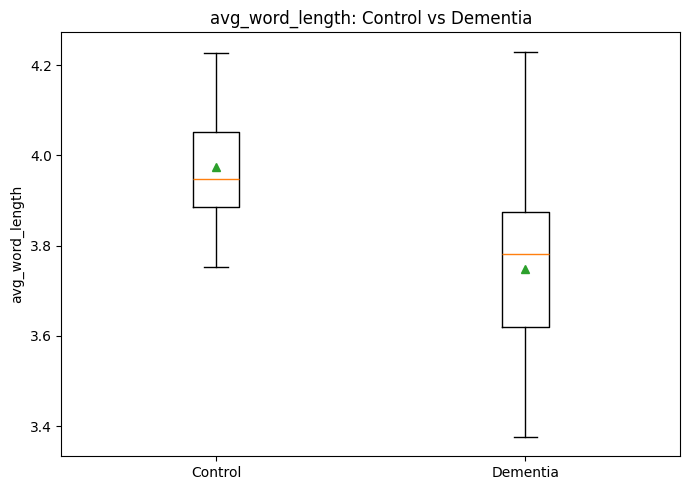

Saved: /content/drive/MyDrive/NeuroSense_NLP_Colab/distilbert_frozen_genuine_chat_v1/figure_linguistic_avg_word_length.png


/tmp/ipykernel_1241/955750823.py:28: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


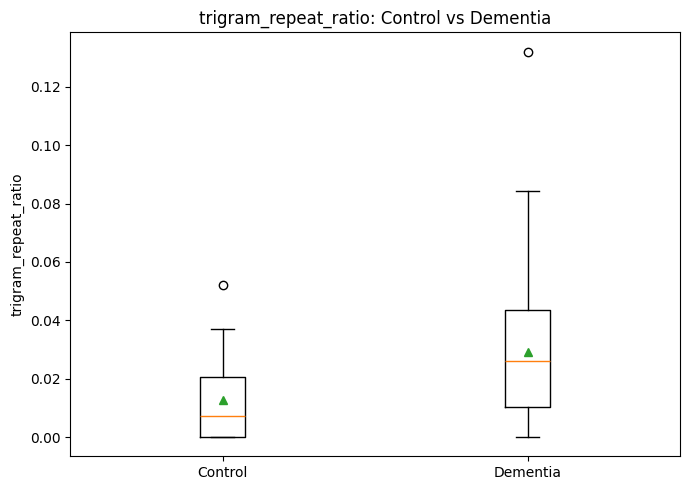

Saved: /content/drive/MyDrive/NeuroSense_NLP_Colab/distilbert_frozen_genuine_chat_v1/figure_linguistic_trigram_repeat_ratio.png


/tmp/ipykernel_1241/955750823.py:28: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


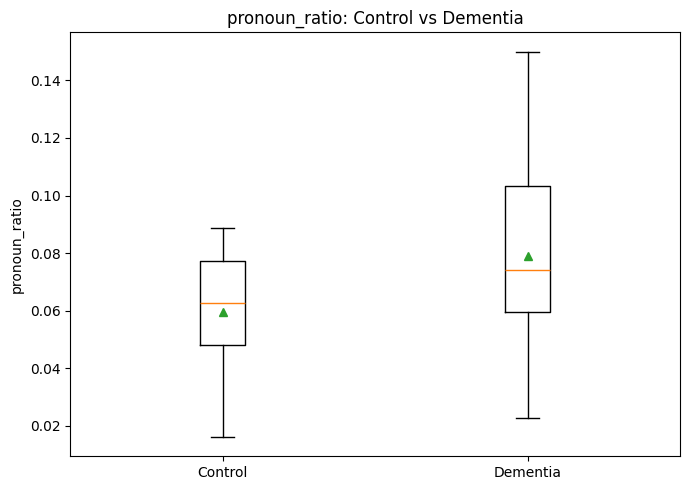

Saved: /content/drive/MyDrive/NeuroSense_NLP_Colab/distilbert_frozen_genuine_chat_v1/figure_linguistic_pronoun_ratio.png


/tmp/ipykernel_1241/955750823.py:28: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


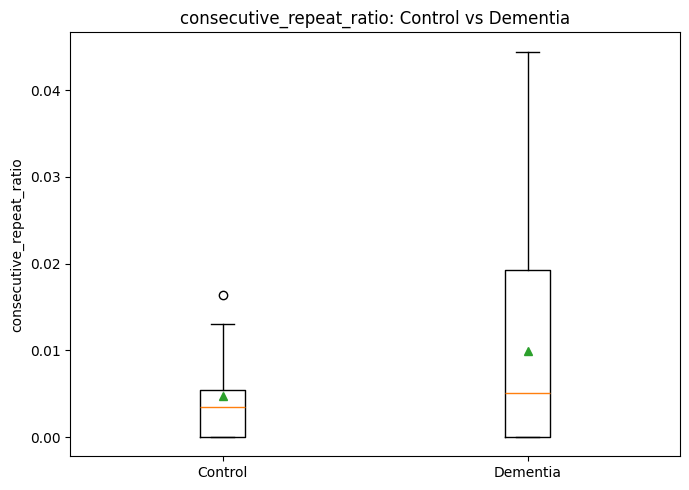

Saved: /content/drive/MyDrive/NeuroSense_NLP_Colab/distilbert_frozen_genuine_chat_v1/figure_linguistic_consecutive_repeat_ratio.png


/tmp/ipykernel_1241/955750823.py:28: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


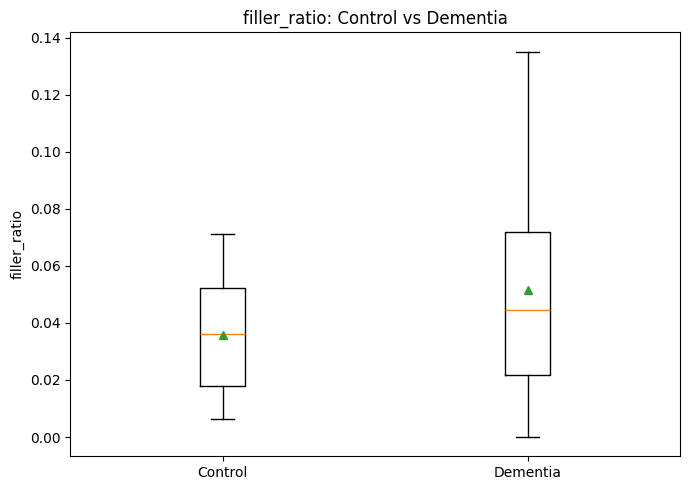

Saved: /content/drive/MyDrive/NeuroSense_NLP_Colab/distilbert_frozen_genuine_chat_v1/figure_linguistic_filler_ratio.png


/tmp/ipykernel_1241/955750823.py:28: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


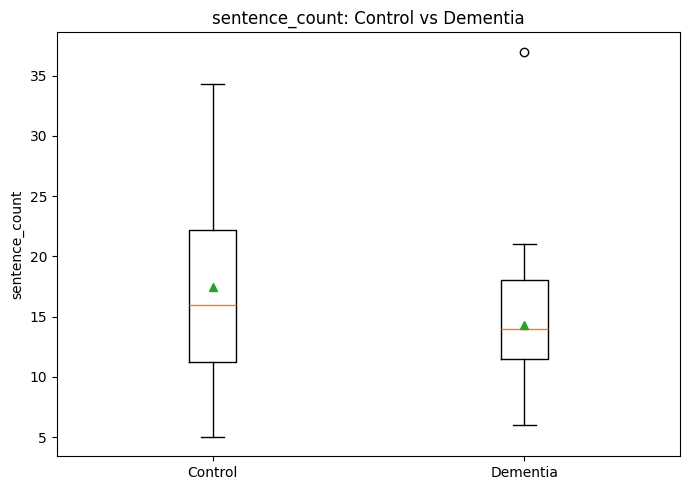

Saved: /content/drive/MyDrive/NeuroSense_NLP_Colab/distilbert_frozen_genuine_chat_v1/figure_linguistic_sentence_count.png


In [14]:
# ============================================================
# CELL 15 — PAPER-READY LINGUISTIC FEATURE PLOTS
# ============================================================

import matplotlib.pyplot as plt

top_features = (
    linguistic_comparison
    .sort_values(
        "abs_standardized_mean_difference",
        ascending=False
    )
    .head(6)["feature"]
    .tolist()
)

print("Plotting:")
for feature in top_features:
    print(" -", feature)

for feature in top_features:

    plt.figure(figsize=(7, 5))

    control_values = control_rows[feature].to_numpy()
    dementia_values = dementia_rows[feature].to_numpy()

    plt.boxplot(
        [control_values, dementia_values],
        labels=["Control", "Dementia"],
        showmeans=True
    )

    plt.ylabel(feature)
    plt.title(
        f"{feature}: Control vs Dementia"
    )

    plt.tight_layout()

    safe_name = (
        feature
        .replace("/", "_")
        .replace(" ", "_")
    )

    output_path = (
        RUN_DIR /
        f"figure_linguistic_{safe_name}.png"
    )

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", output_path)

PAPER-READY LINGUISTIC RESULT
Feature: avg_word_length
Control n: 18
Dementia n: 33
Control mean: 3.9735
Dementia mean: 3.7484
Mean difference (dementia - control): -0.2251
SMD: -1.1780
Raw p-value: 0.000173
FDR-adjusted p-value: 0.004336


/tmp/ipykernel_1241/317936908.py:100: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


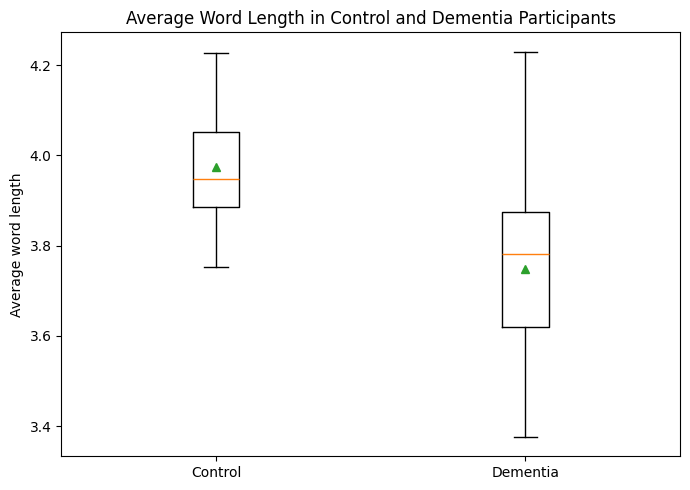


Saved:
/content/drive/MyDrive/NeuroSense_NLP_Colab/distilbert_frozen_genuine_chat_v1/paper_ready_avg_word_length_result.csv
/content/drive/MyDrive/NeuroSense_NLP_Colab/distilbert_frozen_genuine_chat_v1/figure_avg_word_length_control_vs_dementia.png


In [15]:
# ============================================================
# CELL 16 — FINAL PAPER-READY LINGUISTIC RESULT
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FEATURE = "avg_word_length"

# Safety checks
if FEATURE not in participant_analysis.columns:
    raise RuntimeError(
        f"Required feature '{FEATURE}' is missing."
    )

if "statistical_results" not in globals():
    raise RuntimeError(
        "Run Cell 14 first so statistical_results exists."
    )

row = statistical_results[
    statistical_results["feature"] == FEATURE
]

if row.empty:
    raise RuntimeError(
        f"No statistical result found for {FEATURE}."
    )

row = row.iloc[0]

control_values = pd.to_numeric(
    participant_analysis.loc[
        participant_analysis["label"] == "control",
        FEATURE
    ],
    errors="coerce"
).dropna()

dementia_values = pd.to_numeric(
    participant_analysis.loc[
        participant_analysis["label"] == "dementia",
        FEATURE
    ],
    errors="coerce"
).dropna()

# Summary statistics
summary = pd.DataFrame([{
    "feature": FEATURE,
    "control_n": len(control_values),
    "dementia_n": len(dementia_values),
    "control_mean": control_values.mean(),
    "dementia_mean": dementia_values.mean(),
    "control_median": control_values.median(),
    "dementia_median": dementia_values.median(),
    "control_iqr": control_values.quantile(0.75) -
                   control_values.quantile(0.25),
    "dementia_iqr": dementia_values.quantile(0.75) -
                    dementia_values.quantile(0.25),
    "mean_difference_dementia_minus_control":
        dementia_values.mean() - control_values.mean(),
    "smd": row["smd"],
    "p_value": row["p_value"],
    "p_fdr": row["p_fdr"]
}])

summary_path = (
    RUN_DIR /
    "paper_ready_avg_word_length_result.csv"
)

summary.to_csv(
    summary_path,
    index=False
)

# Print final result
print("=" * 70)
print("PAPER-READY LINGUISTIC RESULT")
print("=" * 70)

print(f"Feature: {FEATURE}")
print(f"Control n: {len(control_values)}")
print(f"Dementia n: {len(dementia_values)}")
print(f"Control mean: {control_values.mean():.4f}")
print(f"Dementia mean: {dementia_values.mean():.4f}")
print(
    f"Mean difference (dementia - control): "
    f"{dementia_values.mean() - control_values.mean():.4f}"
)
print(f"SMD: {row['smd']:.4f}")
print(f"Raw p-value: {row['p_value']:.6f}")
print(f"FDR-adjusted p-value: {row['p_fdr']:.6f}")

# Publication figure
plt.figure(figsize=(7, 5))

plt.boxplot(
    [control_values, dementia_values],
    labels=["Control", "Dementia"],
    showmeans=True
)

plt.ylabel("Average word length")
plt.title(
    "Average Word Length in Control and Dementia Participants"
)

plt.tight_layout()

figure_path = (
    RUN_DIR /
    "figure_avg_word_length_control_vs_dementia.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSaved:")
print(summary_path)
print(figure_path)

In [16]:
# ============================================================
# CELL 17 — FINAL NLP ERROR ANALYSIS
# NO TRAINING / NO TEST DATA
# ============================================================

import pandas as pd
import numpy as np

# Safety checks
required_columns = {
    "participant_id",
    "label",
    "probability_distilbert_only",
    "prediction_distilbert_only",
    "error_type",
    "n_recordings"
}

missing = required_columns - set(participant_analysis.columns)

if missing:
    raise RuntimeError(
        f"Missing required columns: {sorted(missing)}"
    )

# ------------------------------------------------------------
# 1. Show the actual misclassified participants
# ------------------------------------------------------------

misclassified = participant_analysis[
    participant_analysis["error_type"].isin(["FP", "FN"])
].copy()

misclassified["confidence_from_0_5"] = (
    misclassified["probability_distilbert_only"] - 0.5
).abs()

misclassified = misclassified.sort_values(
    ["error_type", "confidence_from_0_5"],
    ascending=[True, False]
)

print("=" * 70)
print("FINAL NLP ERROR ANALYSIS")
print("=" * 70)

print("\nMisclassified participants:")
display(
    misclassified[
        [
            "participant_id",
            "label",
            "error_type",
            "probability_distilbert_only",
            "confidence_from_0_5",
            "n_recordings"
        ]
    ]
)

# ------------------------------------------------------------
# 2. Compare linguistic features:
#    Correct vs incorrect participants
# ------------------------------------------------------------

correct = participant_analysis[
    participant_analysis["correct"] == True
].copy()

incorrect = participant_analysis[
    participant_analysis["correct"] == False
].copy()

rows = []

for feature in feature_columns:

    correct_values = pd.to_numeric(
        correct[feature],
        errors="coerce"
    ).dropna()

    incorrect_values = pd.to_numeric(
        incorrect[feature],
        errors="coerce"
    ).dropna()

    if len(correct_values) == 0 or len(incorrect_values) == 0:
        continue

    rows.append({
        "feature": feature,
        "correct_mean": correct_values.mean(),
        "incorrect_mean": incorrect_values.mean(),
        "correct_median": correct_values.median(),
        "incorrect_median": incorrect_values.median(),
        "difference_incorrect_minus_correct":
            incorrect_values.mean() - correct_values.mean(),
        "smd_incorrect_vs_correct":
            pooled_smd(
                incorrect_values,
                correct_values
            )
    })

error_feature_analysis = pd.DataFrame(rows)

error_feature_analysis["abs_smd"] = (
    error_feature_analysis[
        "smd_incorrect_vs_correct"
    ].abs()
)

error_feature_analysis = error_feature_analysis.sort_values(
    "abs_smd",
    ascending=False
).reset_index(drop=True)

print("\nTop feature differences between correct and incorrect cases:")

display(
    error_feature_analysis[
        [
            "feature",
            "correct_mean",
            "incorrect_mean",
            "smd_incorrect_vs_correct"
        ]
    ].head(10)
)

# ------------------------------------------------------------
# 3. Save final error-analysis artifacts
# ------------------------------------------------------------

misclassified_path = (
    RUN_DIR /
    "paper_ready_nlp_misclassified_participants.csv"
)

error_feature_path = (
    RUN_DIR /
    "paper_ready_nlp_error_feature_analysis.csv"
)

misclassified.to_csv(
    misclassified_path,
    index=False
)

error_feature_analysis.to_csv(
    error_feature_path,
    index=False
)

print("\nSaved:")
print(misclassified_path)
print(error_feature_path)

FINAL NLP ERROR ANALYSIS

Misclassified participants:


,participant_id,label,error_type,probability_distilbert_only,confidence_from_0_5,n_recordings
37,578,dementia,FN,0.000238,0.499762,1
32,466,dementia,FN,0.001697,0.498303,2
28,338,dementia,FN,0.009518,0.490482,1
21,244,dementia,FN,0.017048,0.482952,1
9,120,dementia,FN,0.032999,0.467001,4
2,043,dementia,FN,0.117510,0.382490,1
24,282,dementia,FN,0.250967,0.249033,3
4,055,control,FP,0.968455,0.468455,1
12,129,control,FP,0.617166,0.117166,1



Top feature differences between correct and incorrect cases:


,feature,correct_mean,incorrect_mean,smd_incorrect_vs_correct
0,stopword_ratio,0.310137,0.342647,0.819645
1,honore_stat,1599.946206,1925.371527,0.796399
2,mattr,0.918521,0.895814,-0.743206
3,pronoun_ratio,0.075737,0.055624,-0.690725
4,hapax_ratio,0.693062,0.744166,0.683335
5,polarity,0.013059,0.072000,0.492440
6,question_count,1.025000,0.481481,-0.456297
7,consecutive_repeat_ratio,0.008887,0.004463,-0.444462
8,avg_word_length,3.811393,3.904743,0.429451
9,trigram_repeat_ratio,0.024760,0.017043,-0.307407



Saved:
/content/drive/MyDrive/NeuroSense_NLP_Colab/distilbert_frozen_genuine_chat_v1/paper_ready_nlp_misclassified_participants.csv
/content/drive/MyDrive/NeuroSense_NLP_Colab/distilbert_frozen_genuine_chat_v1/paper_ready_nlp_error_feature_analysis.csv


In [17]:
# ============================================================
# CELL 18 — MASTER PAPER-READY NLP RESULTS
# NO TRAINING / NO NEW EXPERIMENT
# ============================================================

import json
import pandas as pd

# ------------------------------------------------------------
# Confirm the expected objects exist
# ------------------------------------------------------------

required_objects = [
    "participant_analysis",
    "statistical_results",
    "sentiment_comparison",
    "misclassified"
]

missing = [
    obj for obj in required_objects
    if obj not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing objects: {missing}. "
        "Run the previous analysis cells first."
    )

# ------------------------------------------------------------
# Reconstruct participant-level classification metrics
# ------------------------------------------------------------

actual = participant_analysis["actual_numeric"]
predicted = participant_analysis["prediction_distilbert_only"]

tn = int(((actual == 0) & (predicted == 0)).sum())
fp = int(((actual == 0) & (predicted == 1)).sum())
fn = int(((actual == 1) & (predicted == 0)).sum())
tp = int(((actual == 1) & (predicted == 1)).sum())

accuracy = (tp + tn) / len(actual)

sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)

balanced_accuracy = (
    sensitivity + specificity
) / 2

precision = tp / (tp + fp)

f1 = (
    2 * precision * sensitivity /
    (precision + sensitivity)
)

# ------------------------------------------------------------
# Identify statistically significant linguistic features
# ------------------------------------------------------------

significant_features = statistical_results[
    statistical_results["significant_fdr_0.05"]
].copy()

# ------------------------------------------------------------
# Build master summary
# ------------------------------------------------------------

master_results = {
    "dataset": {
        "recordings": 92,
        "participants": 51,
        "control_participants": int(
            (participant_analysis["label"] == "control").sum()
        ),
        "dementia_participants": int(
            (participant_analysis["label"] == "dementia").sum()
        )
    },

    "distilbert_validation": {
        "accuracy": accuracy,
        "balanced_accuracy": balanced_accuracy,
        "dementia_recall": sensitivity,
        "control_specificity": specificity,
        "precision": precision,
        "f1": f1,
        "true_negative": tn,
        "false_positive": fp,
        "false_negative": fn,
        "true_positive": tp
    },

    "linguistic_analysis": {
        "features_tested": len(statistical_results),
        "fdr_significant_features": len(significant_features),
        "significant_feature_names":
            significant_features["feature"].tolist()
    },

    "avg_word_length": {
        "control_mean": float(
            significant_features.iloc[0]["control_mean"]
        ),
        "dementia_mean": float(
            significant_features.iloc[0]["dementia_mean"]
        ),
        "smd": float(
            significant_features.iloc[0]["smd"]
        ),
        "raw_p": float(
            significant_features.iloc[0]["p_value"]
        ),
        "fdr_p": float(
            significant_features.iloc[0]["p_fdr"]
        )
    },

    "sentiment": {
        "features": sentiment_comparison[
            "feature"
        ].tolist()
    },

    "error_analysis": {
        "misclassified_participants":
            len(misclassified),
        "false_negatives": fn,
        "false_positives": fp,
        "high_confidence_errors": int(
            (
                misclassified["confidence_from_0_5"]
                > 0.40
            ).sum()
        )
    }
}

master_path = (
    RUN_DIR /
    "NEUROSENSE_NLP_MASTER_RESULTS.json"
)

with open(master_path, "w", encoding="utf-8") as f:
    json.dump(
        master_results,
        f,
        indent=2
    )

print("=" * 70)
print("NEUROSENSE NLP — MASTER RESULTS")
print("=" * 70)

print(
    f"Accuracy:           {accuracy:.4f}"
)
print(
    f"Balanced accuracy:  {balanced_accuracy:.4f}"
)
print(
    f"Dementia recall:    {sensitivity:.4f}"
)
print(
    f"Control specificity:{specificity:.4f}"
)
print(
    f"Precision:          {precision:.4f}"
)
print(
    f"F1:                 {f1:.4f}"
)

print("\nLinguistic features tested:", len(statistical_results))
print(
    "FDR-significant:",
    significant_features["feature"].tolist()
)

print(
    "\nMaster file saved to:",
    master_path
)

NEUROSENSE NLP — MASTER RESULTS
Accuracy:           0.8235
Balanced accuracy:  0.8384
Dementia recall:    0.7879
Control specificity:0.8889
Precision:          0.9286
F1:                 0.8525

Linguistic features tested: 25
FDR-significant: ['avg_word_length']

Master file saved to: /content/drive/MyDrive/NeuroSense_NLP_Colab/distilbert_frozen_genuine_chat_v1/NEUROSENSE_NLP_MASTER_RESULTS.json
